In [1]:
%load_ext autoreload
%autoreload 2

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

rng = np.random.default_rng(0)
pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 40)
H = pd.Timedelta                                       # shorthand: H("30min"), H("3h")

# -- plotting style (same palette as the course tutorials) ---------------------------
INK, INK2, MUTED = "#0b0b0b", "#52514e", "#898781"
GRID, BASELINE, SURFACE = "#e1e0d9", "#c3c2b7", "#fcfcfb"
BLUE, ORANGE, RED = "#2a78d6", "#eb6834", "#e34948"   # series / fit / negative
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE,
    "axes.edgecolor": BASELINE, "axes.labelcolor": INK2,
    "axes.titlecolor": INK, "axes.titlesize": 12, "axes.titleweight": "bold",
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.axisbelow": True,
    "xtick.color": MUTED, "ytick.color": MUTED,
    "xtick.labelcolor": INK2, "ytick.labelcolor": INK2,
    "font.family": "sans-serif", "figure.dpi": 110,
})
print("numpy", np.__version__, "| pandas", pd.__version__)

numpy 2.5.5 | pandas 3.1.1


# Project — Personalized meal-insulin dosing in Type 1 Diabetes
**Notebook 1 — Data loading and preprocessing (AZT1D dataset)**

People with Type 1 Diabetes (T1D) produce no insulin of their own. Before every meal they decide how many units of
rapid-acting insulin to take — the **meal bolus**. Too little leaves glucose high for hours; too much causes
**hypoglycaemia**, which can become dangerous within minutes. The right dose depends on the meal, on the current glucose,
on insulin still active from earlier doses and, above all, on **how this person's body responds to insulin**, which
differs a lot from one person to another.

**Project question:** *given a patient's dosing history, can a linear model recommend the meal bolus that keeps
post-meal glucose in range?*

This notebook turns the raw pump and glucose-sensor time series into a tidy table with **one row per meal episode**:
pre-meal features $\mathbf{x}$, the delivered dose $y$, and the post-meal outcome that tells us whether that dose worked.

| Notebook | Content |
|---|---|
| **1 — preprocessing (this one)** | raw data → cleaned event streams → meal episodes → outcomes, features, label → `data/processed/azt1d_meal_episodes.csv` |
| 2 — linear regression | temporal split per patient, baselines, linear model, diagnostics, interpretation |
| 3 — logistic regression (later) | risk of hypoglycaemia after a meal |

## 1. Problem setup

**Unit of analysis.** A *meal episode* $e$ of patient $p$ starts at time $t_0$ (first carbohydrate entry) and ends at
$t_1$ (last entry belonging to the same meal).

**Label.** $y_{p,e}$ = total **manual** bolus insulin (units, U) delivered for the meal — the dose the patient chose,
usually with the help of the pump's bolus calculator.

**Features.** $\mathbf{x}_{p,e}$ uses only information available **at or before $t_0$**: the meal's carbohydrates, the
glucose level and trend, insulin and carbohydrates still active from earlier events, the time of day, the device mode,
the patient profile and the patient's **own dosing history** (previous meals only).

**Model (Notebook 2).**
$$
y_{p,e} \;=\; \beta_0 + \boldsymbol\beta^\top \mathbf{x}_{p,e} + \varepsilon_{p,e}
$$

**Learning from the meals that worked.** The data contain no "correct" dose — only the dose that was taken, and some of
those doses were wrong. We therefore train on meals whose dose *worked*: no hypoglycaemia, and glucose back in the target
range three hours later,
$$
\text{good}_{p,e} \;=\; \mathbb{1}\Big\{\min_{t\,\in\,[t_0,\;t_1+3\text{h}]} G(t) \,\ge\, 70\ \text{mg/dL}
\;\;\wedge\;\; 70 \,\le\, G(t_1+3\text{h}) \,\le\, 180\ \text{mg/dL}\Big\},
$$
and whose outcome is not confounded by later food or insulin (a **clean** window, §7). 70–180 mg/dL is the
international consensus target range for continuous glucose monitoring [2].

**Personalized setting.** The model is meant for a patient who already has a dosing **history**. It is evaluated on each
patient's *later* meals after learning from their *earlier* ones (temporal split) — not on people it has never seen.

> ⚠️ **Leakage rule of this project.** Anything measured after $t_0$ (post-meal glucose, `good`, `hypo_3h`, …) is used
> **only to select training rows or as a label** — never as a feature.

## 2. The dataset: AZT1D

**AZT1D** [1] contains real-world data from **25 adults with T1D** followed at Mayo Clinic Arizona. All of them use an
**automated insulin delivery (AID)** system: a Tandem t:slim X2 pump running the Control-IQ algorithm [3], paired with a
Dexcom G6 continuous glucose monitor (CGM). Each participant contributed about six weeks of free-living data.

* one CSV per subject: a row every 5 minutes (CGM) plus a row for each bolus;
* times are **local Arizona time** — Arizona does not observe daylight saving time, so there are no clock jumps;
* licence CC BY 4.0 — Mendeley Data, DOI [10.17632/gk9m674wcx.1](https://doi.org/10.17632/gk9m674wcx.1).

**Why this dataset.** The pump's bolus calculator stores the carbohydrates entered and the insulin delivered **in the same
record**, split into a *food* part and a *correction* part, so the label does not have to be inferred from a total
insulin signal. The data are also balanced across patients (see `plano-do-projeto.md` for the comparison with
HUPA-UCM, BrisT1D and T1D-UOM).

**Automated insulin delivery is a confounder.** Control-IQ raises or lowers basal insulin and gives small automatic
correction boluses by itself, so part of a good post-meal outcome is the algorithm's merit and not only the meal bolus.
§7 handles automatic boluses explicitly.

The next cell downloads the archive (~776 MB, mostly PDF figures) **only if the CSVs are not on disk yet**, and extracts
only the `CGM Records` folder.

In [2]:
from urllib.request import urlretrieve
from zipfile import ZipFile

RAW_DIR  = Path("data/raw/azt1d")
CSV_DIR  = RAW_DIR / "AZT1D 2025" / "CGM Records"
ZIP_PATH = RAW_DIR / "AZT1D_2025.zip"
ZIP_URL  = ("https://data.mendeley.com/public-files/datasets/gk9m674wcx/files/"
            "b02a20be-27c4-4dd0-8bb5-9171c66262fb/file_downloaded")

if not CSV_DIR.exists():
    RAW_DIR.mkdir(parents=True, exist_ok=True)
    if not ZIP_PATH.exists():
        print("downloading AZT1D (~776 MB) ...")
        urlretrieve(ZIP_URL, ZIP_PATH)
    with ZipFile(ZIP_PATH) as z:
        members = [m for m in z.namelist()
                   if m.startswith("AZT1D 2025/CGM Records/") and m.endswith(".csv")]
        z.extractall(RAW_DIR, members=members)

files = sorted(CSV_DIR.glob("Subject */Subject *.csv"), key=lambda f: int(f.stem.split()[-1]))
print(f"{len(files)} subject files in {CSV_DIR}")

25 subject files in data/raw/azt1d/AZT1D 2025/CGM Records


## 3. Raw variables — definitions and datatypes

| Column | Unit | Meaning | Notes |
|---|---|---|---|
| `EventDateTime` | local time | timestamp of the row | CGM rows every ~5 min; bolus rows at the bolus time |
| `CGM` | mg/dL | interstitial glucose (Dexcom G6) | the sensor clips at 40 (LOW) and 400 (HIGH) |
| `Basal` | U/h | programmed basal rate | extracted hourly from PDF reports by OCR → errors (§4.3) |
| `BolusType` | — | how the bolus was given | `Standard`, `BLE Standard Bolus` (phone app), `Automatic Bolus/Correction` (Control-IQ), `Extended …`, `Quick`; the suffix `/Correction` means it includes a correction part |
| `TotalBolusInsulinDelivered` | U | bolus insulin delivered | |
| `FoodDelivered` | U | part of the bolus that covers carbohydrates | |
| `CorrectionDelivered` | U | part of the bolus that corrects high glucose | |
| `CarbSize` | g | carbohydrates entered in the bolus calculator | the patient's own estimate |
| `DeviceMode` | — | Control-IQ activity mode | `sleep`, `exercise`; empty = normal. Not exported for every subject |

The subject number is an **identifier, not a feature**: we keep it as `pid` only to group rows by patient.

In [3]:
COLS = ["EventDateTime", "CGM", "Basal", "BolusType", "TotalBolusInsulinDelivered",
        "FoodDelivered", "CorrectionDelivered", "CarbSize", "DeviceMode"]

frames = []
for f in files:
    d = pd.read_csv(f, low_memory=False)
    d = d.rename(columns={"Readings (CGM / BGM)": "CGM"})   # Subject 14 uses a different header
    d["pid"] = int(f.stem.split()[-1])
    frames.append(d[["pid"] + COLS])

raw = pd.concat(frames, ignore_index=True)
raw["t"] = pd.to_datetime(raw["EventDateTime"])
raw = (raw.drop(columns="EventDateTime")
          .sort_values(["pid", "t"], kind="stable")
          .reset_index(drop=True))

print(f"raw table: {len(raw):,} rows x {raw.shape[1]} columns, {raw.pid.nunique()} patients\n")
print(raw.dtypes.to_string())
raw.head()

raw table: 306,712 rows x 10 columns, 25 patients

pid                                    int64
CGM                                  float64
Basal                                float64
BolusType                                str
TotalBolusInsulinDelivered           float64
FoodDelivered                        float64
CorrectionDelivered                  float64
CarbSize                             float64
DeviceMode                            object
t                             datetime64[us]


,pid,CGM,Basal,BolusType,TotalBolusInsulinDelivered,FoodDelivered,CorrectionDelivered,CarbSize,DeviceMode,t
0,1,151.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2023-12-08 00:04:00
1,1,152.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2023-12-08 00:09:00
2,1,156.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2023-12-08 00:14:00
3,1,158.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2023-12-08 00:19:00
4,1,160.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2023-12-08 00:24:00


## 4. Data integrity: duplicates, placeholders and implausible values

Before building anything, inspect the raw table for:
1. **Duplicate rows** — the same record exported twice would count a bolus twice.
2. **Placeholder values** — codes such as `0` or misspelled categories that actually mean "missing".
3. **Implausible values** — numbers outside what physiology or the device allows.
4. **Inconsistencies** between columns that should agree.

### 4.1 Duplicate rows

In [4]:
n_before = len(raw)
dup = raw.duplicated(keep="first")
print(f"exact duplicate rows: {dup.sum():,} ({dup.mean():.1%} of the table)")
print("by patient:", raw.loc[dup, "pid"].value_counts().head(8).to_dict())

# example: one 18.33 U bolus exported several times in the same minute
display(raw[raw.duplicated(keep=False) & raw.TotalBolusInsulinDelivered.gt(0)].head(6))

raw = raw[~dup].reset_index(drop=True)
print(f"after removing exact duplicates: {len(raw):,} rows ({n_before - len(raw):,} dropped)")

same_time = raw.duplicated(["pid", "t"], keep=False)
print(f"rows that share (patient, timestamp) but are not identical: {same_time.sum():,} "
      "-> CGM: median per timestamp (§6.1); boluses: kept as separate events")

exact duplicate rows: 5,189 (1.7% of the table)
by patient: {15: 2041, 3: 861, 17: 305, 10: 288, 14: 195, 6: 166, 21: 149, 23: 148}


,pid,CGM,Basal,BolusType,TotalBolusInsulinDelivered,FoodDelivered,CorrectionDelivered,CarbSize,DeviceMode,t
6234,1,190.0,2.2,Standard,18.33,18.33,0.0,55.0,NaN,2023-12-30 08:59:00
6235,1,190.0,2.2,Standard,18.33,18.33,0.0,55.0,NaN,2023-12-30 08:59:00
6236,1,190.0,2.2,Standard,18.33,18.33,0.0,55.0,NaN,2023-12-30 08:59:00
6237,1,190.0,2.2,Standard,18.33,18.33,0.0,55.0,NaN,2023-12-30 08:59:00
6238,1,190.0,2.2,Standard,18.33,18.33,0.0,55.0,NaN,2023-12-30 08:59:00
6239,1,190.0,2.2,Standard,18.33,18.33,0.0,55.0,NaN,2023-12-30 08:59:00


after removing exact duplicates: 301,523 rows (5,189 dropped)
rows that share (patient, timestamp) but are not identical: 994 -> CGM: median per timestamp (§6.1); boluses: kept as separate events


### 4.2 Placeholder values

Subject 8's export fills empty cells of `BolusType` and `DeviceMode` with the string `0`, and one subject has the
misspelled mode `sleepsleep`. Both are recoded: `0` → missing, `sleepsleep` → `sleep`.

In [5]:
for col in ["BolusType", "DeviceMode"]:
    raw[col] = raw[col].astype("string").str.strip()

is_zero = raw["BolusType"].eq("0").fillna(False).astype(bool)
print(f"BolusType == '0': {is_zero.sum():,} rows (patients {sorted(raw.loc[is_zero, 'pid'].unique().tolist())}),",
      f"insulin on those rows: {raw.loc[is_zero, 'TotalBolusInsulinDelivered'].sum():.1f} U")
print("DeviceMode before:", raw.DeviceMode.value_counts(dropna=False).to_dict())

raw.loc[is_zero, "BolusType"] = pd.NA
raw["DeviceMode"] = raw["DeviceMode"].replace({"0": pd.NA, "sleepsleep": "sleep"})
print("DeviceMode after: ", raw.DeviceMode.value_counts(dropna=False).to_dict())

mode_recorded = raw.groupby("pid")["DeviceMode"].apply(lambda s: s.notna().any()).rename("mode_recorded")
print(f"patients whose export records the device mode: {mode_recorded.sum()} of {len(mode_recorded)}"
      f" (missing for {sorted(mode_recorded.index[~mode_recorded])})")

BolusType == '0': 7,770 rows (patients [8]), insulin on those rows: 0.0 U
DeviceMode before: {<NA>: 237541, 'sleep': 56833, '0': 5261, 'exercise': 1855, 'sleepsleep': 33}
DeviceMode after:  {<NA>: 242802, 'sleep': 56866, 'exercise': 1855}
patients whose export records the device mode: 20 of 25 (missing for [1, 5, 7, 11, 22])


### 4.3 Implausible basal rates (OCR errors)

The dataset authors extracted the hourly basal rate from PDF reports with optical character recognition. Adult basal
rates are typically 0.3–3 U/h; values in the hundreds are digits read without the decimal point (`825` was probably
`0.825`). The original value cannot be recovered with certainty, so anything above **10 U/h** becomes missing.

In [6]:
print("basal rate (U/h) quantiles:", raw.Basal.quantile([.5, .9, .95, .99]).round(2).to_dict())
bad_basal = raw["Basal"] > 10
print(f"basal > 10 U/h: {bad_basal.sum():,} rows; by patient:",
      raw.loc[bad_basal, "pid"].value_counts().to_dict())
print("most frequent implausible values:", raw.loc[bad_basal, "Basal"].value_counts().head(6).to_dict())

raw.loc[bad_basal, "Basal"] = np.nan
print(f"basal missing after cleaning: {raw.Basal.isna().mean():.0%} of rows "
      "(will be imputed with the TRAINING median in Notebook 2)")

basal rate (U/h) quantiles: {0.5: 0.69, 0.9: 2.25, 0.95: 3.15, 0.99: 896.0}
basal > 10 U/h: 6,176 rows; by patient: {10: 3600, 23: 2244, 16: 204, 19: 84, 3: 19, 1: 12, 9: 12, 25: 1}
most frequent implausible values: {300.0: 216, 825.0: 200, 700.0: 143, 900.0: 104, 1650.0: 72, 557.0: 36}
basal missing after cleaning: 37% of rows (will be imputed with the TRAINING median in Notebook 2)


### 4.4 Sensor limits and bolus decomposition

* The Dexcom G6 reports glucose between 40 and 400 mg/dL; readings at the limits are **censored** (the true value may be
  lower/higher). They are few and kept as they are.
* By construction `TotalBolusInsulinDelivered` = `FoodDelivered` + `CorrectionDelivered` when the bolus calculator is
  used. When it does not hold, the bolus was entered as a plain number of units, without the calculator.

In [7]:
print(f"CGM range: {raw.CGM.min():.0f}-{raw.CGM.max():.0f} mg/dL | "
      f"LOW (40): {(raw.CGM == 40).sum()} readings | HIGH (400): {(raw.CGM == 400).sum()} readings")

bol_rows = raw[raw.TotalBolusInsulinDelivered > 0]
parts = bol_rows.FoodDelivered.fillna(0) + bol_rows.CorrectionDelivered.fillna(0)
mismatch = (bol_rows.TotalBolusInsulinDelivered - parts).abs() > 0.05
print(f"\nboluses: {len(bol_rows):,} | total != food + correction: {mismatch.sum():,} ({mismatch.mean():.0%}),"
      f" of which with carbohydrates entered: {(mismatch & bol_rows.CarbSize.gt(0)).sum()}")

family = (bol_rows.BolusType.str.extract(r"^(Automatic|BLE Standard|Standard|Extended|Quick)", expand=False)
                  .fillna("other"))
print("\nbolus type x carbohydrates entered:")
print(pd.crosstab(family, bol_rows.CarbSize.gt(0).map({True: "with carbs", False: "no carbs"}), margins=True))

CGM range: 40-400 mg/dL | LOW (40): 151 readings | HIGH (400): 50 readings

boluses: 10,564 | total != food + correction: 1,658 (16%), of which with carbohydrates entered: 59

bolus type x carbohydrates entered:
CarbSize      no carbs  with carbs    All
BolusType                                
Automatic         3455           0   3455
BLE Standard       465        1044   1509
Extended             8          62     70
Quick               14           0     14
Standard          2385        3131   5516
All               6327        4237  10564


### 4.5 Follow-up and CGM coverage per patient

The Dexcom G6 should give 288 readings a day. Coverage = readings received / readings expected over the follow-up.

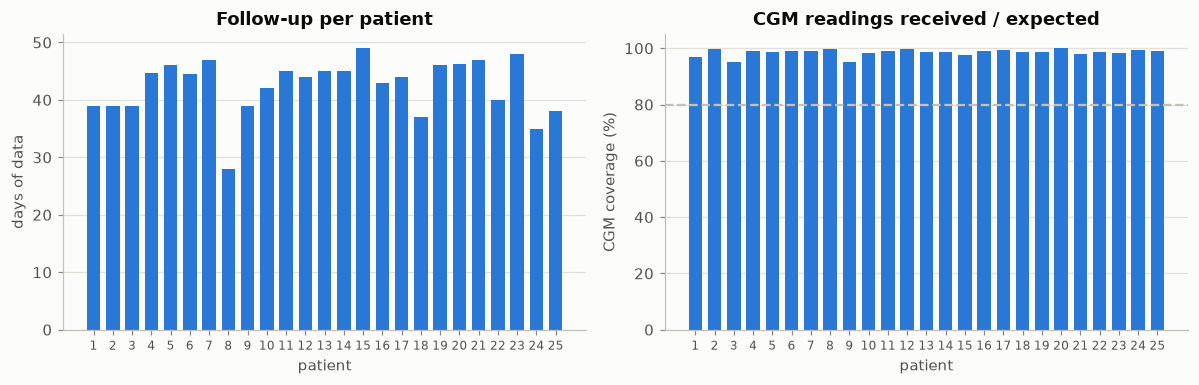

follow-up: median 44 days (range 28-49) | CGM coverage: median 99%, minimum 95%


In [8]:
cov = (raw.dropna(subset=["CGM"]).drop_duplicates(["pid", "t"])
          .groupby("pid").agg(first=("t", "min"), last=("t", "max"), n=("t", "size")))
cov["days"] = (cov["last"] - cov["first"]).dt.total_seconds() / 86400
cov["coverage"] = cov["n"] / (cov["days"] * 288)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.6))
ax1.bar(cov.index.astype(str), cov.days, color=BLUE, width=0.7)
ax1.set_xlabel("patient"); ax1.set_ylabel("days of data"); ax1.set_title("Follow-up per patient")
ax2.bar(cov.index.astype(str), cov.coverage * 100, color=BLUE, width=0.7)
ax2.axhline(80, color=BASELINE, lw=1.5, ls="--")
ax2.set_ylim(0, 105); ax2.set_xlabel("patient"); ax2.set_ylabel("CGM coverage (%)")
ax2.set_title("CGM readings received / expected")
for ax in (ax1, ax2):
    ax.tick_params(axis="x", labelsize=8)
    ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

print(f"follow-up: median {cov.days.median():.0f} days (range {cov.days.min():.0f}-{cov.days.max():.0f}) | "
      f"CGM coverage: median {cov.coverage.median():.0%}, minimum {cov.coverage.min():.0%}")

## 5. Patient profile (Table I of the AZT1D paper)

The CSVs carry no patient information. Table I of the paper [1] gives **HbA1c, sex and age** for each subject. There is
**no body weight, insulin-to-carbohydrate ratio or insulin sensitivity factor**, so "how this body responds to insulin"
has to be learned from the patient's **history** (§8).

Sex is nominal with $K = 2$ levels → **one** dummy column, `male` (reference = female).

In [9]:
# Table I of [1]: subject -> (HbA1c %, sex, age in years)
TABLE_I = {
     1: (7.2, "Male", 65),    2: (6.6, "Female", 67),  3: (5.1, "Male", 65),    4: (7.2, "Female", 69),
     5: (6.5, "Male", 80),    6: (6.6, "Female", 77),  7: (6.8, "Male", 36),    8: (7.2, "Female", 66),
     9: (8.2, "Female", 54), 10: (7.7, "Female", 71), 11: (7.3, "Male", 59),   12: (6.6, "Male", 43),
    13: (6.7, "Male", 80),   14: (5.0, "Female", 32), 15: (5.9, "Female", 52), 16: (6.3, "Male", 40),
    17: (7.1, "Female", 66), 18: (6.9, "Male", 65),   19: (6.2, "Male", 27),   20: (6.7, "Female", 61),
    21: (6.4, "Female", 46), 22: (6.5, "Female", 46), 23: (5.7, "Female", 67), 24: (6.7, "Male", 74),
    25: (6.8, "Male", 72),
}
profile = pd.DataFrame.from_dict(TABLE_I, orient="index", columns=["a1c", "sex", "age"]).rename_axis("pid")
profile["male"] = (profile["sex"] == "Male").astype(float)          # K=2 -> one dummy, ref = Female
profile = profile.join(mode_recorded)

print(profile[["a1c", "age"]].describe().loc[["mean", "std", "min", "max"]].round(1))
print("\nsex:", profile.sex.value_counts().to_dict())

      a1c   age
mean  6.6  59.2
std   0.7  15.1
min   5.0  27.0
max   8.2  80.0

sex: {'Female': 13, 'Male': 12}


## 6. From time series to meal episodes

### 6.1 Three tidy event streams

* **CGM** — one reading per (patient, timestamp); when two different rows share a timestamp, their median.
* **Boluses** — one row per bolus (`TotalBolusInsulinDelivered > 0`), flagged as **manual** (chosen by the patient) or
  **automatic** (given by Control-IQ).
* **Carbohydrate entries** — rows with `CarbSize > 0`.

In [10]:
cgm = raw.dropna(subset=["CGM"]).groupby(["pid", "t"])["CGM"].median().rename("g")
G = {pid: s.droplevel("pid") for pid, s in cgm.groupby(level="pid")}            # per-patient glucose series

boluses = raw.loc[raw.TotalBolusInsulinDelivered > 0,
                  ["pid", "t", "BolusType", "TotalBolusInsulinDelivered", "FoodDelivered",
                   "CorrectionDelivered", "CarbSize"]].copy()
boluses.columns = ["pid", "t", "type", "dose", "food", "corr", "carbs"]
boluses[["food", "corr", "carbs"]] = boluses[["food", "corr", "carbs"]].fillna(0.0)
boluses["auto"] = boluses["type"].str.startswith("Automatic").fillna(False).astype(bool)
boluses["extended"] = boluses["type"].str.startswith("Extended").fillna(False).astype(bool)
boluses["ep"] = -1                                    # meal episode the bolus belongs to (filled in §6.2)
boluses = boluses.reset_index(drop=True)

carb_entries = (raw.loc[raw.CarbSize > 0, ["pid", "t", "CarbSize"]]
                   .rename(columns={"CarbSize": "carbs"}).reset_index(drop=True))

mode = raw.dropna(subset=["DeviceMode"]).groupby(["pid", "t"])["DeviceMode"].first()
MODE = {pid: s.droplevel("pid") for pid, s in mode.groupby(level="pid")}
basal = raw.dropna(subset=["Basal"]).groupby(["pid", "t"])["Basal"].last()
BASAL = {pid: s.droplevel("pid") for pid, s in basal.groupby(level="pid")}

print(f"CGM readings: {len(cgm):,}")
print(f"boluses: {len(boluses):,}  (manual {(~boluses.auto).sum():,}, automatic {boluses.auto.sum():,}, "
      f"extended {boluses.extended.sum()})")
print(f"carbohydrate entries: {len(carb_entries):,}")

CGM readings: 300,923
boluses: 10,564  (manual 7,109, automatic 3,455, extended 70)
carbohydrate entries: 4,254


### 6.2 Meal episodes and the label

Patients often enter one meal in several pieces (main course, then dessert). Carbohydrate entries less than
**30 min** apart are merged into one **episode** $[t_0, t_1]$ with the summed carbohydrates.

Each **manual** bolus within 30 min of an episode, $t_b \in [t_0 - 30\,\text{min},\; t_1 + 30\,\text{min}]$, is assigned
to it (to the nearest one if two episodes qualify). This captures a correction given just before eating and a top-up
right after. The label and its two parts are
$$
y_e = \sum_{b\,\in\,e} \text{dose}_b, \qquad
y^{\text{food}}_e = \sum_{b\,\in\,e} \text{food}_b, \qquad
y^{\text{corr}}_e = \sum_{b\,\in\,e} \text{corr}_b .
$$
Automatic boluses are **never** part of the label: the patient did not choose them.

In [11]:
MERGE_GAP = H("30min")    # carbohydrate entries closer than this belong to the same meal
DOSE_WIN  = H("30min")    # a manual bolus this close to an episode is part of its dose
EPOCH = pd.Timestamp("2020-01-01")
minutes = lambda t: ((t - EPOCH) / H("1min")).to_numpy(dtype=float)


def build_episodes(entries):
    """Merge one patient's carbohydrate entries into meal episodes."""
    e = entries.sort_values("t")
    ep_id = (e["t"].diff() > MERGE_GAP).cumsum()
    return (e.groupby(ep_id).agg(t0=("t", "min"), t1=("t", "max"),
                                 carbs_g=("carbs", "sum"), n_entries=("t", "size"))
              .reset_index(drop=True))


def assign_boluses(ep, bol):
    """Position of the episode each bolus belongs to (-1 = none), nearest episode within DOSE_WIN."""
    if len(ep) == 0 or len(bol) == 0:
        return np.full(len(bol), -1)
    tb = minutes(bol["t"])[:, None]
    t0, t1 = minutes(ep["t0"])[None, :], minutes(ep["t1"])[None, :]
    dist = np.where(tb < t0, t0 - tb, np.where(tb > t1, tb - t1, 0.0))     # 0 inside the episode
    ok = dist <= DOSE_WIN / H("1min")
    best = np.where(ok, dist, np.inf).argmin(axis=1)                         # ties -> earlier episode
    return np.where(ok.any(axis=1), best, -1)


episodes = []
for pid, entries in carb_entries.groupby("pid"):
    ep = build_episodes(entries)
    man = boluses[(boluses.pid == pid) & ~boluses.auto]
    pos = assign_boluses(ep, man)
    boluses.loc[man.index, "ep"] = pos

    grp = man.assign(ep=pos).query("ep >= 0").groupby("ep")
    ep["dose_u"]       = grp["dose"].sum()
    ep["dose_food_u"]  = grp["food"].sum()
    ep["dose_corr_u"]  = grp["corr"].sum()
    ep["n_boluses"]    = grp.size()
    ep["has_extended"] = grp["extended"].any()
    ep[["dose_u", "dose_food_u", "dose_corr_u", "n_boluses"]] = (
        ep[["dose_u", "dose_food_u", "dose_corr_u", "n_boluses"]].fillna(0))
    ep["has_extended"] = ep["has_extended"].fillna(False).astype(bool)
    ep.insert(0, "ep", np.arange(len(ep)))
    ep.insert(0, "pid", pid)
    episodes.append(ep)

episodes = pd.concat(episodes, ignore_index=True)
episodes["usable_dose"] = (episodes.dose_u > 0) & ~episodes.has_extended

print(f"{len(carb_entries):,} carbohydrate entries -> {len(episodes):,} meal episodes "
      f"({(episodes.n_entries > 1).sum():,} merged from 2+ entries)")
print(f"episodes with a manual dose: {(episodes.dose_u > 0).sum():,} | with no manual bolus: "
      f"{(episodes.dose_u == 0).sum():,} | with an extended bolus: {episodes.has_extended.sum():,}")
print(f"patients with at least one episode: {episodes.pid.nunique()} "
      f"(no carbohydrate entries at all: {sorted(set(profile.index) - set(episodes.pid))})")

4,254 carbohydrate entries -> 3,743 meal episodes (396 merged from 2+ entries)
episodes with a manual dose: 3,742 | with no manual bolus: 1 | with an extended bolus: 63
patients with at least one episode: 24 (no carbohydrate entries at all: [23])


**One day of one patient.** The glucose curve with the meals (carbohydrates), the manual boluses chosen by the patient and
the small automatic boluses added by Control-IQ.

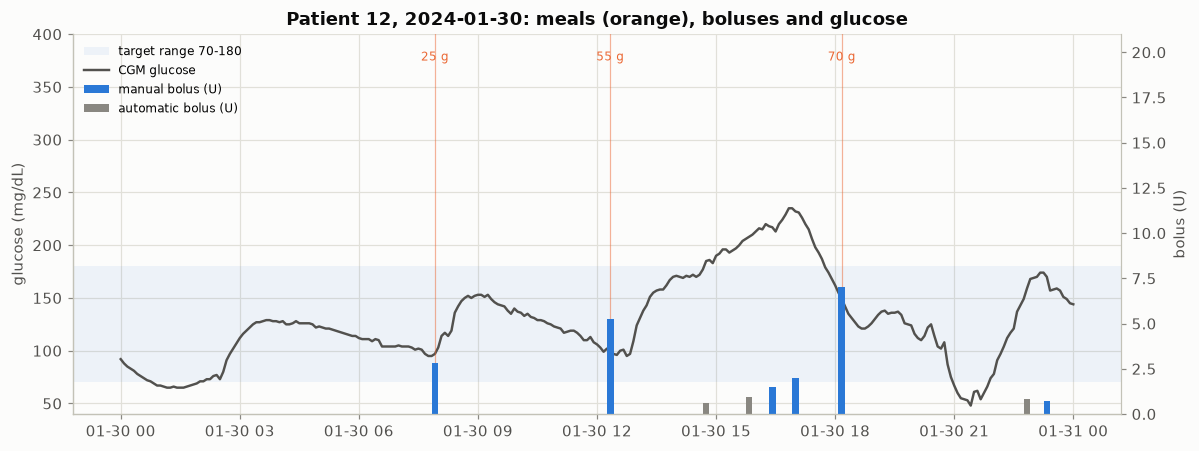

In [12]:
ex_pid = 12
ep_ex = episodes[episodes.pid == ex_pid]
per_day = ep_ex.groupby(ep_ex.t0.dt.normalize()).size()
busy = per_day[per_day >= 3].index
ex_day = busy[len(busy) // 2]                                   # a typical day in the middle of follow-up
lo, hi = ex_day, ex_day + H("1D")

g = G[ex_pid].loc[lo:hi]
b = boluses[(boluses.pid == ex_pid) & boluses.t.between(lo, hi)]
c = carb_entries[(carb_entries.pid == ex_pid) & carb_entries.t.between(lo, hi)]

fig, ax = plt.subplots(figsize=(11, 4.2))
ax.axhspan(70, 180, color=BLUE, alpha=0.07, lw=0, label="target range 70-180")
ax.plot(g.index, g.values, color=INK2, lw=1.6, label="CGM glucose")
for t, grams in zip(c.t, c.carbs):
    ax.annotate(f"{grams:.0f} g", (t, 375), ha="center", fontsize=8, color=ORANGE)
    ax.axvline(t, color=ORANGE, lw=0.8, alpha=0.5)
ax.set_ylim(40, 400); ax.set_ylabel("glucose (mg/dL)")

ax2 = ax.twinx()
ax2.spines["right"].set_visible(True); ax2.grid(False)
w = H("10min")
ax2.bar(b.t[~b.auto], b.dose[~b.auto], width=w, color=BLUE, label="manual bolus (U)")
ax2.bar(b.t[b.auto], b.dose[b.auto], width=w, color=MUTED, label="automatic bolus (U)")
ax2.set_ylim(0, max(1, b.dose.max()) * 3); ax2.set_ylabel("bolus (U)")

h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, loc="upper left", fontsize=8, frameon=False)
ax.set_title(f"Patient {ex_pid}, {ex_day:%Y-%m-%d}: meals (orange), boluses and glucose")
plt.tight_layout()
plt.show()

## 7. What happened after the meal — outcomes (never features)

For each episode we look at the window $[t_0,\; t_1 + 3\,\text{h}]$:

| Variable | Definition |
|---|---|
| `cgm_cov_post` | share of the expected 5-min CGM readings present in the window |
| `g_min_3h`, `g_max_3h` | lowest / highest glucose in the window (mg/dL) |
| `g_3h` | glucose at $t_1 + 3\,\text{h}$ (mean of the readings within ±5 min) |
| `hypo_3h` | $\mathbb{1}\{g_{\min} < 70\}$ |
| `good` | no hypoglycaemia **and** $70 \le g_{3h} \le 180$ |
| `n_later_carbs`, `n_later_manual`, `n_later_auto` | food entries / manual boluses / automatic boluses in $(t_1 + 30\,\text{min},\; t_1 + 3\,\text{h}]$ |
| `clean_strict` | no later food and no later bolus of **any** kind |
| `clean_manual` | no later food and no later **manual** bolus (automatic corrections allowed) |

A later snack or correction bolus can "rescue" a wrong dose, so the outcome of a meal is only trusted when its window is
**clean**. `clean_strict` also drops the meals that Control-IQ had to correct automatically — cleaner but smaller;
`clean_manual` keeps them (sensitivity analysis in Notebook 2).

In [13]:
POST, CLEAN_FROM = H("3h"), H("30min")


def outcomes_for_patient(ep, g, bol, ent):
    rows = []
    for e in ep.itertuples():
        end = e.t1 + POST
        post = g.loc[e.t0:end]
        expected = (end - e.t0) / H("5min") + 1
        g3 = g.loc[end - H("5min"):end + H("5min")]
        lb = bol[(bol.t > e.t1 + CLEAN_FROM) & (bol.t <= end)]
        lc = ent[(ent.t > e.t1 + CLEAN_FROM) & (ent.t <= end)]
        rows.append(dict(cgm_cov_post=len(post) / expected,
                         g_min_3h=post.min(), g_max_3h=post.max(),
                         g_3h=g3.mean() if len(g3) else np.nan,
                         n_later_carbs=len(lc),
                         n_later_manual=int((~lb.auto).sum()), n_later_auto=int(lb.auto.sum())))
    return pd.DataFrame(rows, index=ep.index)


out = [outcomes_for_patient(ep, G[pid], boluses[boluses.pid == pid], carb_entries[carb_entries.pid == pid])
       for pid, ep in episodes.groupby("pid")]
episodes = episodes.join(pd.concat(out))

episodes["hypo_3h"]      = episodes.g_min_3h < 70
episodes["good"]         = ~episodes.hypo_3h & episodes.g_3h.between(70, 180)
episodes["clean_manual"] = (episodes.n_later_carbs == 0) & (episodes.n_later_manual == 0)
episodes["clean_strict"] = episodes.clean_manual & (episodes.n_later_auto == 0)

base = episodes[episodes.usable_dose & (episodes.cgm_cov_post >= 0.8)]
print(f"episodes with a usable dose and >= 80% CGM coverage after the meal: {len(base):,}")
print(f"  hypoglycaemia (<70) within 3 h: {base.hypo_3h.mean():.0%} | glucose > 180 at 3 h: {(base.g_3h > 180).mean():.0%}"
      f" | good: {base.good.mean():.0%}")
print(f"  clean_strict: {base.clean_strict.mean():.0%} | clean_manual: {base.clean_manual.mean():.0%}")

episodes with a usable dose and >= 80% CGM coverage after the meal: 3,568
  hypoglycaemia (<70) within 3 h: 9% | glucose > 180 at 3 h: 25% | good: 66%
  clean_strict: 31% | clean_manual: 52%


**Average glucose around clean meals**, split by outcome. The "good" meals rise moderately and come back into range; the
other two groups show what a dose that was too large (hypoglycaemia) or too small (still high at 3 h) looks like.

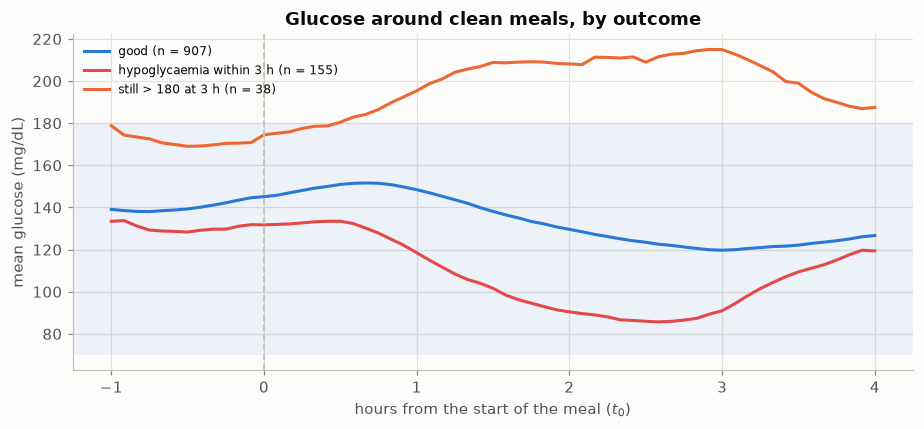

In [14]:
def aligned_curve(rows, before=H("1h"), after=H("4h")):
    """Mean CGM curve aligned on t0, in 5-min bins."""
    pieces = []
    for e in rows.itertuples():
        s = G[e.pid].loc[e.t0 - before:e.t0 + after]
        rel = ((s.index - e.t0).total_seconds() / 300).round() * 5          # minutes from t0
        pieces.append(pd.Series(s.to_numpy(), index=rel))
    return pd.concat(pieces).groupby(level=0).mean()


sel = base[base.clean_strict]
groups = [("good", sel[sel.good], BLUE),
          ("hypoglycaemia within 3 h", sel[sel.hypo_3h], RED),
          ("still > 180 at 3 h", sel[~sel.hypo_3h & (sel.g_3h > 180)], ORANGE)]

fig, ax = plt.subplots(figsize=(8.5, 4))
ax.axhspan(70, 180, color=BLUE, alpha=0.07, lw=0)
for name, rows, color in groups:
    curve = aligned_curve(rows)
    ax.plot(curve.index / 60, curve.values, color=color, lw=2, label=f"{name} (n = {len(rows)})")
ax.axvline(0, color=BASELINE, ls="--", lw=1.2)
ax.set_xlabel("hours from the start of the meal ($t_0$)")
ax.set_ylabel("mean glucose (mg/dL)")
ax.set_title("Glucose around clean meals, by outcome")
ax.legend(fontsize=8, frameon=False)
plt.tight_layout()
plt.show()

## 8. Features — information available before the meal

All features use data **up to $t_0$**, plus the carbohydrates of the meal itself (the patient types them into the
calculator).

| Feature | Definition | Unit |
|---|---|---|
| `carbs_g` | carbohydrates of the episode | g |
| `g0` | last CGM reading in $[t_0 - 15\,\text{min},\; t_0]$ | mg/dL |
| `g_trend_30` | $g_0$ minus the glucose 30 min earlier | mg/dL per 30 min |
| `g_mean_3h` | mean glucose in $[t_0 - 3\,\text{h},\; t_0)$ | mg/dL |
| `iob_u` | **insulin on board**: boluses in $[t_0 - 4\,\text{h},\; t_0)$ that are not part of this meal, with linear decay $\sum_b \text{dose}_b \big(1 - \tfrac{t_0 - t_b}{4\,\text{h}}\big)$ | U |
| `cob_g` | **carbohydrates on board**: earlier entries in $[t_0 - 3\,\text{h},\; t_0)$, linear decay over 3 h | g |
| `min_since_prev_meal` | time since the previous episode ended (capped at 12 h) | min |
| `auto_insulin_2h` | automatic (Control-IQ) bolus insulin in the previous 2 h | U |
| `basal_u_h` | programmed basal rate at $t_0$ (missing values imputed in Notebook 2 with the **training** median) | U/h |
| `hour_sin`, `hour_cos` | time of day on the unit circle, $\big(\sin\tfrac{2\pi h}{24},\; \cos\tfrac{2\pi h}{24}\big)$ | — |
| `period_breakfast`, `period_dinner`, `period_night` | dummies for 05–11 h, 16–22 h, 22–05 h; reference = lunch (11–16 h) | 0/1 |
| `exercise_2h` | exercise mode active in the previous 2 h | 0/1 |
| `sleep_mode` | sleep mode active at $t_0$ | 0/1 |
| `mode_recorded` | the patient's export records the device mode (otherwise the two mode features are always 0) | 0/1 |
| `age`, `male`, `a1c` | profile (Table I) | years, 0/1, % |
| `hist_n_meals` | number of the patient's previous episodes with a usable dose | count |
| `hist_ratio` | **personal insulin-to-carbohydrate ratio** from previous meals, $\sum y \,/\, \sum \text{carbs}$ | U/g |
| `hist_n_good`, `hist_ratio_good` | same, using only previous **good & clean** meals whose outcome was already known at $t_0$ | count, U/g |

The `hist_*` features answer "how does this body respond to insulin?". They are computed with an **expanding window over
the patient's own past**, so they never look into the future, for any split that keeps time order within a patient.

> Relationships between the features and the label are explored in Notebook 2, **on the training split only**.

In [15]:
IOB_DUR, COB_DUR = H("4h"), H("3h")


def features_for_patient(pid, ep):
    g, md = G[pid], MODE.get(pid)
    bs = BASAL.get(pid)
    bol = boluses[boluses.pid == pid]
    ent = carb_entries[carb_entries.pid == pid]
    rows, prev_t1 = [], None
    for e in ep.itertuples():
        t0 = e.t0
        pre = g.loc[t0 - H("15min"):t0]
        g30 = g.loc[t0 - H("35min"):t0 - H("25min")]
        g_hist = g.loc[t0 - H("3h"):t0 - H("1s")]
        g0 = pre.iloc[-1] if len(pre) else np.nan

        before = bol[(bol.t >= t0 - IOB_DUR) & (bol.t < t0) & (bol.ep != e.ep)]   # not this meal's own dose
        iob = (before.dose * (1 - (t0 - before.t) / IOB_DUR)).sum()
        prev_c = ent[(ent.t >= t0 - COB_DUR) & (ent.t < t0)]
        cob = (prev_c.carbs * (1 - (t0 - prev_c.t) / COB_DUR)).sum()
        auto2h = bol[bol.auto & (bol.t >= t0 - H("2h")) & (bol.t < t0)].dose.sum()

        b_now = bs.loc[t0 - H("1h"):t0] if bs is not None else pd.Series(dtype=float)
        m2h = md.loc[t0 - H("2h"):t0] if md is not None else pd.Series(dtype="string")
        m_now = md.loc[t0 - H("15min"):t0] if md is not None else pd.Series(dtype="string")
        in_win = bol[(bol.t >= e.t0 - DOSE_WIN) & (bol.t <= e.t1 + DOSE_WIN)]

        rows.append(dict(
            g0=g0,
            g_trend_30=g0 - g30.mean() if len(g30) else np.nan,
            g_mean_3h=g_hist.mean() if len(g_hist) else np.nan,
            iob_u=iob, cob_g=cob, auto_insulin_2h=auto2h,
            min_since_prev_meal=min((t0 - prev_t1) / H("1min"), 720.0) if prev_t1 is not None else 720.0,
            basal_u_h=b_now.iloc[-1] if len(b_now) else np.nan,
            exercise_2h=float((m2h == "exercise").any()),
            sleep_mode=float((m_now == "sleep").any()),
            auto_in_dose_window=int(in_win.auto.sum()),
        ))
        prev_t1 = e.t1
    return pd.DataFrame(rows, index=ep.index)


def history_for_patient(ep):
    """Expanding-window personal ratios: only episodes that happened before t0."""
    t0 = ep.t0.to_numpy(); known_at = (ep.t1 + POST).to_numpy()
    use = ep.usable_dose.to_numpy()
    good = (ep.good & ep.clean_strict & (ep.cgm_cov_post >= 0.8)).to_numpy() & use
    dose, carbs = ep.dose_u.to_numpy(), ep.carbs_g.to_numpy()
    rows = []
    for i in range(len(ep)):
        past = np.zeros(len(ep), bool); past[:i] = True
        p_all = past & use
        p_good = past & good & (known_at <= t0[i])          # outcome already observed at t0
        rows.append(dict(
            hist_n_meals=int(p_all.sum()),
            hist_ratio=dose[p_all].sum() / carbs[p_all].sum() if p_all.any() else np.nan,
            hist_n_good=int(p_good.sum()),
            hist_ratio_good=dose[p_good].sum() / carbs[p_good].sum() if p_good.any() else np.nan))
    return pd.DataFrame(rows, index=ep.index)


episodes = episodes.sort_values(["pid", "t0"]).reset_index(drop=True)
feat = pd.concat([features_for_patient(pid, ep) for pid, ep in episodes.groupby("pid")])
hist = pd.concat([history_for_patient(ep) for _, ep in episodes.groupby("pid")])
episodes = episodes.join(feat).join(hist)

# time of day: cyclic encoding + meal-period dummies (reference = lunch)
hour = episodes.t0.dt.hour + episodes.t0.dt.minute / 60
episodes["hour_sin"] = np.sin(2 * np.pi * hour / 24)
episodes["hour_cos"] = np.cos(2 * np.pi * hour / 24)
period = pd.cut(hour, bins=[0, 5, 11, 16, 22, 24], right=False,
                labels=["night", "breakfast", "lunch", "dinner", "night2"]).astype(str).replace({"night2": "night"})
episodes["period"] = period
for p in ["breakfast", "dinner", "night"]:
    episodes[f"period_{p}"] = (period == p).astype(float)

episodes = episodes.join(profile[["age", "male", "a1c", "mode_recorded"]], on="pid")
episodes["mode_recorded"] = episodes["mode_recorded"].astype(float)

print(f"feature table: {len(episodes):,} episodes")
print("meal period:", episodes.period.value_counts().to_dict())
print(f"missing g0: {episodes.g0.isna().sum()} | missing basal: {episodes.basal_u_h.isna().mean():.0%} "
      f"| episodes with exercise in the previous 2 h: {int(episodes.exercise_2h.sum())}")

feature table: 3,743 episodes
meal period: {'dinner': 1393, 'lunch': 1184, 'breakfast': 1029, 'night': 137}
missing g0: 0 | missing basal: 35% | episodes with exercise in the previous 2 h: 43


## 9. The rows available for the linear regression

Training candidates for Notebook 2 are episodes that pass every filter:
1. a usable label (manual dose > 0, no extended bolus — its insulin is spread over hours);
2. complete CGM around the meal (`g0` present and ≥ 80 % of the post-meal readings);
3. a **clean** post-meal window (`clean_strict`);
4. a **good** outcome.

Notebook 2 adds one more, modelling-side condition: a minimum **history** per patient (`hist_n_meals`) before a meal is
used — the personalized setting of the project.

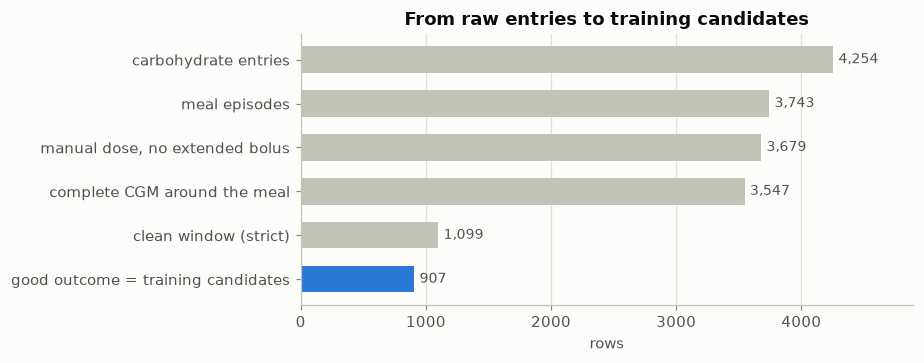

with clean_manual instead of clean_strict: 1,371 candidates (sensitivity analysis)


In [16]:
episodes["cgm_ok"] = (episodes.cgm_cov_post >= 0.8) & episodes.g0.notna() & episodes.g_3h.notna()
episodes["train_candidate"] = episodes.usable_dose & episodes.cgm_ok & episodes.clean_strict & episodes.good

steps = [("carbohydrate entries",            len(carb_entries)),
         ("meal episodes",                    len(episodes)),
         ("manual dose, no extended bolus",   int(episodes.usable_dose.sum())),
         ("complete CGM around the meal",     int((episodes.usable_dose & episodes.cgm_ok).sum())),
         ("clean window (strict)",            int((episodes.usable_dose & episodes.cgm_ok & episodes.clean_strict).sum())),
         ("good outcome = training candidates", int(episodes.train_candidate.sum()))]

fig, ax = plt.subplots(figsize=(8.5, 3.4))
names, values = zip(*steps[::-1])
bars = ax.barh(names, values, color=[BLUE] + [BASELINE] * (len(values) - 1), height=0.6)
for bar, v in zip(bars, values):
    ax.text(v + max(values) * 0.01, bar.get_y() + bar.get_height() / 2, f"{v:,}", va="center", color=INK2, fontsize=9)
ax.set_xlim(0, max(values) * 1.15)
ax.set_xlabel("rows")
ax.set_title("From raw entries to training candidates")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

alt = int((episodes.usable_dose & episodes.cgm_ok & episodes.clean_manual & episodes.good).sum())
print(f"with clean_manual instead of clean_strict: {alt:,} candidates (sensitivity analysis)")

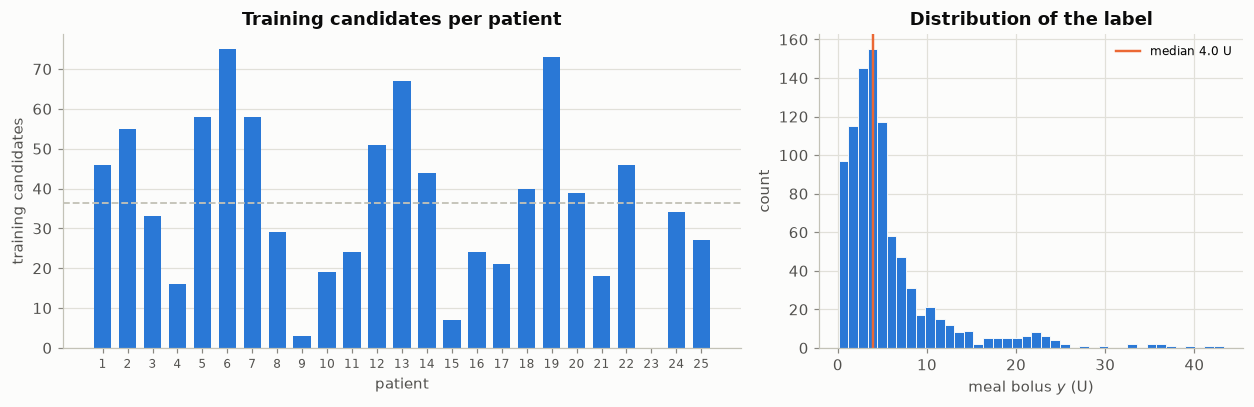

907 candidates from 24 patients | largest patient: 8%, two largest: 16% | patients with >= 30: 14
label: median 4.0 U, IQR 2.4-6.3 U, skewness 2.81 (right tail: large meals)


In [17]:
cand = episodes[episodes.train_candidate]
per_pid = cand.pid.value_counts().reindex(profile.index, fill_value=0)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11.5, 3.8), gridspec_kw={"width_ratios": [1.6, 1]})
ax1.bar(per_pid.index.astype(str), per_pid.values, color=BLUE, width=0.7)
ax1.axhline(per_pid.mean(), color=BASELINE, ls="--", lw=1.2)
ax1.set_xlabel("patient"); ax1.set_ylabel("training candidates")
ax1.set_title("Training candidates per patient")
ax1.tick_params(axis="x", labelsize=8); ax1.grid(axis="x", visible=False)

ax2.hist(cand.dose_u, bins=40, color=BLUE, edgecolor=SURFACE, linewidth=0.6)
ax2.axvline(cand.dose_u.median(), color=ORANGE, lw=1.6, label=f"median {cand.dose_u.median():.1f} U")
ax2.set_xlabel("meal bolus $y$ (U)"); ax2.set_ylabel("count")
ax2.set_title("Distribution of the label")
ax2.legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.show()

top = per_pid.sort_values(ascending=False)
print(f"{len(cand):,} candidates from {int((per_pid > 0).sum())} patients | largest patient: {top.iloc[0] / len(cand):.0%}, "
      f"two largest: {top.iloc[:2].sum() / len(cand):.0%} | patients with >= 30: {int((per_pid >= 30).sum())}")
print(f"label: median {cand.dose_u.median():.1f} U, IQR {cand.dose_u.quantile(.25):.1f}-{cand.dose_u.quantile(.75):.1f} U, "
      f"skewness {cand.dose_u.skew():.2f} (right tail: large meals)")

## 10. Save the processed table

One row per meal episode (**all** episodes, with the filter flags), so Notebook 2 can change any filter without re-running
this notebook.

In [18]:
ID_COLS  = ["pid", "ep", "t0", "t1", "period", "n_entries", "n_boluses"]
FEATURES = ["carbs_g", "g0", "g_trend_30", "g_mean_3h", "iob_u", "cob_g", "min_since_prev_meal",
            "auto_insulin_2h", "basal_u_h", "hour_sin", "hour_cos",
            "period_breakfast", "period_dinner", "period_night",
            "exercise_2h", "sleep_mode", "mode_recorded", "age", "male", "a1c",
            "hist_n_meals", "hist_ratio", "hist_n_good", "hist_ratio_good"]
LABELS   = ["dose_u", "dose_food_u", "dose_corr_u"]
OUTCOMES = ["cgm_cov_post", "g_min_3h", "g_max_3h", "g_3h", "hypo_3h", "good",
            "n_later_carbs", "n_later_manual", "n_later_auto", "clean_strict", "clean_manual"]
FLAGS    = ["has_extended", "auto_in_dose_window", "usable_dose", "cgm_ok", "train_candidate"]

OUT_DIR = Path("data/processed")
OUT_DIR.mkdir(parents=True, exist_ok=True)
table = episodes[ID_COLS + FEATURES + LABELS + OUTCOMES + FLAGS]
table.to_csv(OUT_DIR / "azt1d_meal_episodes.csv", index=False)

print(f"saved {OUT_DIR / 'azt1d_meal_episodes.csv'}: {table.shape[0]:,} episodes x {table.shape[1]} columns")
for name, cols in [("features", FEATURES), ("labels", LABELS), ("outcomes (never features)", OUTCOMES), ("flags", FLAGS)]:
    print(f"  {name:26s} {len(cols):2d}: {', '.join(cols)}")

saved data/processed/azt1d_meal_episodes.csv: 3,743 episodes x 50 columns
  features                   24: carbs_g, g0, g_trend_30, g_mean_3h, iob_u, cob_g, min_since_prev_meal, auto_insulin_2h, basal_u_h, hour_sin, hour_cos, period_breakfast, period_dinner, period_night, exercise_2h, sleep_mode, mode_recorded, age, male, a1c, hist_n_meals, hist_ratio, hist_n_good, hist_ratio_good
  labels                      3: dose_u, dose_food_u, dose_corr_u
  outcomes (never features)  11: cgm_cov_post, g_min_3h, g_max_3h, g_3h, hypo_3h, good, n_later_carbs, n_later_manual, n_later_auto, clean_strict, clean_manual
  flags                       5: has_extended, auto_in_dose_window, usable_dose, cgm_ok, train_candidate


## Summary and next steps

* **Cleaning:** exact duplicate rows removed, placeholder codes recoded, implausible basal rates (OCR errors) set to
  missing, split meals merged into episodes.
* **Label:** manual bolus per meal episode; automatic (Control-IQ) insulin is excluded from the label but kept as context
  (`auto_insulin_2h`) and as an outcome-side confounder (`n_later_auto`).
* **Training rows:** clean meals with a good outcome — the doses that worked.

**Notebook 2 — linear regression** will:
1. require a minimum history per patient and split **in time within each patient** (earlier meals → train, later → test);
2. compare against baselines: the patient's mean dose, and $\text{carbs} \times$ `hist_ratio` (the personal ratio alone);
3. fit the linear model with standardization and training-median imputation, weighting patients equally;
4. evaluate MAE / RMSE / $R^2$ overall and per patient, check the residuals, and interpret the coefficients;
5. run the sensitivity analyses: `clean_manual` instead of `clean_strict`, and all meals instead of good meals only.

## References

1. Khamesian S., Arefeen A., Thompson B. M., Grando M. A., Ghasemzadeh H. *AZT1D: A Real-World Dataset for Type 1
   Diabetes.* arXiv:2506.14789 (2025). Data: Mendeley Data, DOI
   [10.17632/gk9m674wcx.1](https://doi.org/10.17632/gk9m674wcx.1) (CC BY 4.0).
2. Battelino T. et al. *Clinical Targets for Continuous Glucose Monitoring Data Interpretation: Recommendations From the
   International Consensus on Time in Range.* Diabetes Care 42(8):1593–1603 (2019).
3. Brown S. A. et al. *Six-Month Randomized, Multicenter Trial of Closed-Loop Control in Type 1 Diabetes.*
   N Engl J Med 381:1707–1717 (2019).